# Week4_ex1 — Five-bus power flow: Ybus, solvers, generator range, shunt capacitor and DC flow

Reproduces Examples 6.9–6.12, 6.14 and 6.17 from Glover, Overbye & Sarma, *Power System Analysis and Design* (7th ed.), on the five-bus, two-generator system that all six examples share. Reference values come from the textbook tables and the PowerWorld screens printed with each example.

![PowerWorld one-line](Images/Week4_ex1_result_image.png)

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandapower as pp
from pandapower.pypower.dSbus_dV import dSbus_dV

# 1. System constants (Example 6.9, Tables 6.1-6.3)
S_BASE = 100.0          # Assumed MVA Per Unit Base of the case
TOL_MVA = 0.1           # PowerWorld MVA convergence tolerance of the case
F_HZ = 60.0
BUS_KV = {1: 15.0, 2: 345.0, 3: 15.0, 4: 345.0, 5: 345.0}
LINES = [  # from, to, R, X, B (pu on S_BASE), MVA limit
    (2, 4, 0.0090, 0.100, 1.72, 1200.0),
    (2, 5, 0.0045, 0.050, 0.88, 1200.0),
    (4, 5, 0.00225, 0.025, 0.44, 1200.0),
]
TRAFOS = [  # hv bus, lv bus, R, X (pu on S_BASE), MVA limit
    (5, 1, 0.0015, 0.02, 600.0),
    (4, 3, 0.00075, 0.01, 1000.0),
]
IMG = Path("Images")
IMG.mkdir(exist_ok=True)


# 2. pu -> pandapower conversion: length_km = 1, ohm = pu * Z_base, max_i_ka from the MVA limit
def build_net(p_gen3=520.0):
    net = pp.create_empty_network(sn_mva=S_BASE, f_hz=F_HZ)
    bus = {k: pp.create_bus(net, vn_kv=kv, name=f"Bus {k}") for k, kv in BUS_KV.items()}
    pp.create_ext_grid(net, bus[1], vm_pu=1.0, va_degree=0.0, name="Gen 1 (slack)")
    pp.create_gen(net, bus[3], p_mw=p_gen3, vm_pu=1.05, min_q_mvar=-280.0, max_q_mvar=400.0, name="Gen 3")
    pp.create_load(net, bus[2], p_mw=800.0, q_mvar=280.0, name="Load 2")
    pp.create_load(net, bus[3], p_mw=80.0, q_mvar=40.0, name="Load 3")
    for f, t, r, x, b, lim in LINES:
        kv = BUS_KV[f]
        z_base = kv**2 / S_BASE
        pp.create_line_from_parameters(
            net, bus[f], bus[t], length_km=1.0,
            r_ohm_per_km=r * z_base, x_ohm_per_km=x * z_base,
            c_nf_per_km=b / z_base / (2 * math.pi * F_HZ) * 1e9,
            max_i_ka=lim / (math.sqrt(3) * kv), name=f"{f}-{t}")   # MVA / kV = kA
    # 3. Transformers on S_BASE so vk/vkr are the pu impedance in percent; the textbook ignores the delta-wye shift
    for hv, lv, r, x, lim in TRAFOS:
        pp.create_transformer_from_parameters(
            net, bus[hv], bus[lv], sn_mva=S_BASE, vn_hv_kv=BUS_KV[hv], vn_lv_kv=BUS_KV[lv],
            vkr_percent=r * 100, vk_percent=math.hypot(r, x) * 100,
            pfe_kw=0.0, i0_percent=0.0, shift_degree=0.0, name=f"{lv}-{hv}")
    net.line["lim_mva"] = [l[-1] for l in LINES]
    net.trafo["lim_mva"] = [t[-1] for t in TRAFOS]
    return net


def solve(net, **kw):
    pp.runpp(net, **{"enforce_q_lims": True, "tolerance_mva": 1e-8, **kw})
    return net


# 3. PowerWorld "% of MVA limit": max(S_from, S_to) / limit, unlike pandapower's current-based loading_percent
def mva_loading(net):
    rl, rt = net.res_line, net.res_trafo
    s_line = np.maximum(np.hypot(rl.p_from_mw, rl.q_from_mvar), np.hypot(rl.p_to_mw, rl.q_to_mvar))
    s_trafo = np.maximum(np.hypot(rt.p_hv_mw, rt.q_hv_mvar), np.hypot(rt.p_lv_mw, rt.q_lv_mvar))
    return pd.concat([
        pd.Series((s_line / net.line.lim_mva * 100).values, index="Line " + net.line.name),
        pd.Series((s_trafo / net.trafo.lim_mva * 100).values, index="T " + net.trafo.name),
    ])


# 4. Residual band: worst case when every non-slack bus keeps a mismatch up to the MVA tolerance
#    (P at every non-slack bus, Q at PQ buses; effects added in absolute value)
def residual_band(build, measure, tol=TOL_MVA, dc=False):
    def run(n):
        pp.rundcpp(n) if dc else solve(n)
        return n
    base = measure(run(build()))
    band = pd.Series(0.0, index=base.index)
    probe = build()
    pv = set(probe.gen.bus) | set(probe.ext_grid.bus)
    for bus in probe.bus.index.difference(probe.ext_grid.bus):
        for col in (["p_mw"] if dc or bus in pv else ["p_mw", "q_mvar"]):
            worst = pd.Series(0.0, index=base.index)
            for sign in (1, -1):
                net = build()
                pp.create_load(net, bus, **{"p_mw": 0.0, "q_mvar": 0.0, col: sign * tol})
                worst = np.maximum(worst, (measure(run(net)) - base).abs())
            band += worst
    return band


# 5. Comparison table; fails loudly when any row is outside its tolerance.
#    Tolerance = half of the printed digit + residual band: the two errors are independent and stack
def compare(rows):
    df = pd.DataFrame(rows, columns=["Quantity", "pandapower", "Reference", "Tolerance", "Source"])
    df["Abs diff"] = (df.pandapower - df.Reference).abs()
    df["Pass"] = df["Abs diff"] <= df.Tolerance
    assert df.Pass.all(), df.loc[~df.Pass, "Quantity"].tolist()
    return df[["Quantity", "pandapower", "Reference", "Abs diff", "Tolerance", "Pass", "Source"]].round(5)

In [2]:
# 6. Example 6.9 base case solved by Newton-Raphson, checked against Table 6.6
net = solve(build_net())
b = dict(zip(range(1, 6), net.bus.index))


def bus_measure(n):
    rb = n.res_bus
    vals = {f"V{k} [pu]": rb.vm_pu[b[k]] for k in (2, 4, 5)}
    vals.update({f"delta{k} [deg]": rb.va_degree[b[k]] for k in (2, 3, 4, 5)})
    vals.update({"PG1 [MW]": n.res_ext_grid.p_mw.iloc[0], "QG1 [Mvar]": n.res_ext_grid.q_mvar.iloc[0],
                 "QG3 [Mvar]": n.res_gen.q_mvar.iloc[0]})
    return pd.Series(vals)


ref = {"V2 [pu]": 0.834, "V4 [pu]": 1.019, "V5 [pu]": 0.974,
       "delta2 [deg]": -22.407, "delta3 [deg]": -0.597, "delta4 [deg]": -2.834, "delta5 [deg]": -4.548,
       "PG1 [MW]": 394.8, "QG1 [Mvar]": 114.4, "QG3 [Mvar]": 337.6}
digits = {"pu": 5e-4, "deg": 5e-4, "MW": 0.05, "Mvar": 0.05}   # half of the last printed digit (pu x 100)
band = residual_band(build_net, bus_measure)
got = bus_measure(net)
compare([(q, got[q], r, digits[q.split("[")[1][:-1]] + band[q], "Table 6.6") for q, r in ref.items()])

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass,Source
0,V2 [pu],0.83377,0.834,0.00023,0.00067,True,Table 6.6
1,V4 [pu],1.01930,1.019,0.00030,0.00054,True,Table 6.6
2,V5 [pu],0.97429,0.974,0.00029,0.00056,True,Table 6.6
3,delta2 [deg],-22.40642,-22.407,0.00058,0.01352,True,Table 6.6
4,delta3 [deg],-0.59735,-0.597,0.00035,0.00928,True,Table 6.6
5,delta4 [deg],-2.83397,-2.834,0.00003,0.00871,True,Table 6.6
6,delta5 [deg],-4.54788,-4.548,0.00012,0.00556,True,Table 6.6
7,PG1 [MW],394.83876,394.800,0.03876,0.47725,True,Table 6.6
8,QG1 [Mvar],114.28290,114.400,0.11710,0.35188,True,Table 6.6
9,QG3 [Mvar],337.47963,337.600,0.12037,0.41967,True,Table 6.6


In [3]:
# 7. Branch flows against Tables 6.7 and 6.8 (pu x 100 -> MW/Mvar)
def flow_measure(n):
    rl, rt = n.res_line, n.res_trafo
    vals = {}
    for i, name in enumerate(n.line.name):
        f, t = name.split("-")
        vals.update({f"P {f}->{t} [MW]": rl.p_from_mw[i], f"Q {f}->{t} [Mvar]": rl.q_from_mvar[i],
                     f"P {t}->{f} [MW]": rl.p_to_mw[i], f"Q {t}->{f} [Mvar]": rl.q_to_mvar[i]})
    for i, name in enumerate(n.trafo.name):
        lv, hv = name.split("-")
        vals.update({f"P {lv}->{hv} [MW]": rt.p_lv_mw[i], f"Q {lv}->{hv} [Mvar]": rt.q_lv_mvar[i],
                     f"P {hv}->{lv} [MW]": rt.p_hv_mw[i], f"Q {hv}->{lv} [Mvar]": rt.q_hv_mvar[i]})
    return pd.Series(vals)


ref = {"P 2->4 [MW]": -292.0, "Q 2->4 [Mvar]": -139.2, "P 4->2 [MW]": 303.6, "Q 4->2 [Mvar]": 121.6,
       "P 2->5 [MW]": -508.0, "Q 2->5 [Mvar]": -140.8, "P 5->2 [MW]": 525.6, "Q 5->2 [Mvar]": 263.2,
       "P 4->5 [MW]": 134.4, "Q 4->5 [Mvar]": 150.4, "P 5->4 [MW]": -133.2, "Q 5->4 [Mvar]": -182.4,
       "P 1->5 [MW]": 394.8, "Q 1->5 [Mvar]": 114.4, "P 5->1 [MW]": -392.4, "Q 5->1 [Mvar]": -80.4,
       "P 3->4 [MW]": 440.0, "Q 3->4 [Mvar]": 297.6, "P 4->3 [MW]": -438.0, "Q 4->3 [Mvar]": -272.0}


# 8. Display band: Table 6.6 prints V and delta to three decimals, so the flows it implies are only
#    pinned down to how far they move when each printed value shifts by half a digit (pi model, pu x 100)
def flows_from_state(vm, va):
    v = {k: vm[k] * np.exp(1j * np.radians(va[k])) for k in vm}
    out = {}
    for f, t, r, x, bsh in [(f, t, r, x, bb) for f, t, r, x, bb, _ in LINES] + [(lv, hv, r, x, 0.0) for hv, lv, r, x, _ in TRAFOS]:
        y = 1 / (r + 1j * x)
        for a, c in ((f, t), (t, f)):
            s = v[a] * np.conj((v[a] - v[c]) * y + v[a] * 1j * bsh / 2) * S_BASE
            out[f"P {a}->{c} [MW]"], out[f"Q {a}->{c} [Mvar]"] = s.real, s.imag
    return pd.Series(out)


vm = {1: 1.0, 2: 0.834, 3: 1.05, 4: 1.019, 5: 0.974}
va = {1: 0.0, 2: -22.407, 3: -0.597, 4: -2.834, 5: -4.548}
center = flows_from_state(vm, va)
display_band = pd.Series(0.0, index=center.index)
for table, keys in ((vm, (2, 4, 5)), (va, (2, 3, 4, 5))):
    for k in keys:
        worst = pd.Series(0.0, index=center.index)
        for sign in (1, -1):
            table[k] += sign * 5e-4
            worst = np.maximum(worst, (flows_from_state(vm, va) - center).abs())
            table[k] -= sign * 5e-4
        display_band += worst

band = residual_band(build_net, flow_measure)
got = flow_measure(net)
trafo_rows = {q for q in ref if any(s in q for s in ("1->", "->1", "3->", "->3"))}
compare([(q, got[q], r, 0.05 + band[q] + display_band[q], "Table 6.8" if q in trafo_rows else "Table 6.7")
         for q, r in ref.items()])

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass,Source
0,P 2->4 [MW],-291.84114,-292.0,0.15886,0.42974,True,Table 6.7
1,Q 2->4 [Mvar],-139.10536,-139.2,0.09464,0.77563,True,Table 6.7
2,P 4->2 [MW],303.68240,303.6,0.08240,0.44817,True,Table 6.7
3,Q 4->2 [Mvar],121.53837,121.6,0.06163,1.21969,True,Table 6.7
4,P 2->5 [MW],-508.15886,-508.0,0.15886,0.72568,True,Table 6.7
5,Q 2->5 [Mvar],-140.89464,-140.8,0.09464,1.63930,True,Table 6.7
6,P 5->2 [MW],525.66207,525.6,0.06207,0.75520,True,Table 6.7
7,Q 5->2 [Mvar],263.02093,263.2,0.17907,2.31434,True,Table 6.7
8,P 4->5 [MW],134.39859,134.4,0.00141,0.70389,True,Table 6.7
9,Q 4->5 [Mvar],150.35449,150.4,0.04551,4.30790,True,Table 6.7


In [4]:
# 9. Row 2 of Ybus from pandapower's internal matrix vs the hand calculation in Example 6.9
ppc = net._ppc["internal"]
lookup = net._pd2ppc_lookups["bus"]
Ybus = ppc["Ybus"].toarray()
row2 = {k: Ybus[lookup[b[2]], lookup[b[k]]] for k in range(1, 6)}
ref = {1: 0, 2: 2.67828 - 28.4590j, 3: 0, 4: -0.89276 + 9.91964j, 5: -1.78552 + 19.83932j}
rows = []
for k, r in ref.items():
    # the textbook truncates each term to five decimals and prints B22 to four, so allow 1e-4
    rows += [(f"G2{k} [pu]", row2[k].real, r.real, 1e-4, "Example 6.9"),
             (f"B2{k} [pu]", row2[k].imag, r.imag, 1e-4, "Example 6.9")]
compare(rows)

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass,Source
0,G21 [pu],0.00000,0.00000,0.00000,0.0001,True,Example 6.9
1,B21 [pu],0.00000,0.00000,0.00000,0.0001,True,Example 6.9
2,G22 [pu],2.67831,2.67828,0.00003,0.0001,True,Example 6.9
3,B22 [pu],-28.45895,-28.45900,0.00005,0.0001,True,Example 6.9
4,G23 [pu],0.00000,0.00000,0.00000,0.0001,True,Example 6.9
5,B23 [pu],0.00000,0.00000,0.00000,0.0001,True,Example 6.9
6,G24 [pu],-0.89277,-0.89276,0.00001,0.0001,True,Example 6.9
7,B24 [pu],9.91965,9.91964,0.00001,0.0001,True,Example 6.9
8,G25 [pu],-1.78554,-1.78552,0.00002,0.0001,True,Example 6.9
9,B25 [pu],19.83930,19.83932,0.00002,0.0001,True,Example 6.9


In [5]:
# 10. Flat start shared by Examples 6.10 and 6.11: |V| = 1.0 except V3 = 1.05, all angles 0
i = {k: lookup[b[k]] for k in range(1, 6)}
V0 = np.ones(5, dtype=complex)
V0[i[3]] = 1.05
P2, Q2 = -8.0, -2.8

# 11. Example 6.10: one Gauss-Seidel update of V2, equation (6.5.2)
others = sum(Ybus[i[2], i[k]] * V0[i[k]] for k in (1, 3, 4, 5))
V2_gs = ((P2 - 1j * Q2) / np.conj(V0[i[2]]) - others) / Ybus[i[2], i[2]]

# 12. Example 6.11: first Newton-Raphson mismatch and Jacobian term J1_24 = dP2/d(delta4)
S0 = V0 * np.conj(Ybus @ V0)
_, dS_dVa = dSbus_dV(ppc["Ybus"], V0)   # returns (dS/d|V|, dS/d delta)
dP2 = P2 - S0[i[2]].real
J1_24 = dS_dVa.toarray()[i[2], i[4]].real

compare([
    ("|V2(1)| [pu]", abs(V2_gs), 0.96132, 5e-6, "Example 6.10"),
    ("angle V2(1) [deg]", np.degrees(np.angle(V2_gs)), -16.543, 5e-4, "Example 6.10"),
    # P2(x0) = G22 + G24 + G25 = 0 exactly; the textbook's -2.89e-4 comes from cosines of angles printed
    # to three decimals (0.0005 deg x |Y22| = 2.5e-4), so the tolerance covers that rounding
    ("dP2(0) [pu]", dP2, -7.99972, 5e-4, "Example 6.11"),
    ("J1_24(0) [pu]", J1_24, -9.91964, 5e-5, "Example 6.11"),
])

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass,Source
0,|V2(1)| [pu],0.96132,0.96132,0.00000,0.00000,True,Example 6.10
1,angle V2(1) [deg],-16.54295,-16.54300,0.00005,0.00050,True,Example 6.10
2,dP2(0) [pu],-8.00000,-7.99972,0.00028,0.00050,True,Example 6.11
3,J1_24(0) [pu],-9.91965,-9.91964,0.00001,0.00005,True,Example 6.11


In [6]:
# 13. Sections 6.5, 6.6 and 6.9: same answer from four solvers, very different iteration counts
reference = solve(build_net()).res_bus.copy()
rows = []
for alg in ["nr", "fdbx", "fdxb", "gs"]:
    n = solve(build_net(), algorithm=alg, max_iteration=500, tolerance_mva=1e-6)
    rows.append({"Algorithm": alg, "Iterations": n._ppc["iterations"],
                 "Max |dV| vs NR [pu]": (n.res_bus.vm_pu - reference.vm_pu).abs().max(),
                 "Max |d delta| vs NR [deg]": (n.res_bus.va_degree - reference.va_degree).abs().max()})
pd.DataFrame(rows).round(8)

,Algorithm,Iterations,Max |dV| vs NR [pu],Max |d delta| vs NR [deg]
0,nr,4,1.000000e-08,2.800000e-07
1,fdbx,18,7.000000e-08,1.810000e-06
2,fdxb,18,6.000000e-08,1.760000e-06
3,gs,89,1.000000e-08,2.410000e-06


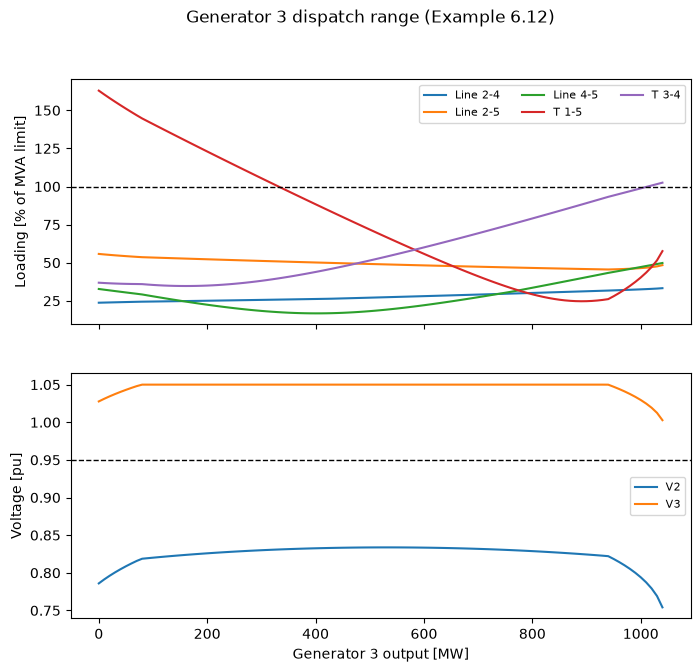

In [7]:
# 14. Example 6.12: sweep generator 3 and track every branch in PowerWorld's MVA-limit percent
rows = []
for p in range(0, 1050, 10):
    n = solve(build_net(p))
    rec = mva_loading(n)
    rec["V2 [pu]"] = n.res_bus.vm_pu[b[2]]
    rec["V3 [pu]"] = n.res_bus.vm_pu[b[3]]
    rec["QG3 [Mvar]"] = n.res_gen.q_mvar.iloc[0]
    rows.append(rec.rename(p))
sweep = pd.DataFrame(rows)
sweep.index.name = "PG3 [MW]"

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
for col in [c for c in sweep.columns if c.startswith(("Line", "T "))]:
    ax1.plot(sweep.index, sweep[col], label=col)
ax1.axhline(100, color="k", ls="--", lw=1)
ax1.set_ylabel("Loading [% of MVA limit]")
ax1.legend(ncol=3, fontsize=8)
ax2.plot(sweep.index, sweep["V2 [pu]"], label="V2")
ax2.plot(sweep.index, sweep["V3 [pu]"], label="V3")
ax2.axhline(0.95, color="k", ls="--", lw=1)
ax2.set_ylabel("Voltage [pu]")
ax2.set_xlabel("Generator 3 output [MW]")
ax2.legend(fontsize=8)
fig.suptitle("Generator 3 dispatch range (Example 6.12)")
fig.savefig(IMG / "Week4_ex1_gen3_range_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
# 15. Bisect the two thermal bounds, with and without generator 3's Mvar limits
def bound(branch, lo, hi, q_lims):
    rising = branch == "T 3-4"     # T 1-5 unloads as PG3 rises, T 3-4 loads up
    for _ in range(40):
        mid = (lo + hi) / 2
        n = build_net(mid)
        pp.runpp(n, enforce_q_lims=q_lims, tolerance_mva=1e-8)
        if (mva_loading(n)[branch] > 100) == rising:
            hi = mid
        else:
            lo = mid
    return mid


def v2_at(p):
    return solve(build_net(p)).res_bus.vm_pu[b[2]]


lower, upper = bound("T 1-5", 0, 520, True), bound("T 3-4", 520, 1040, True)
pd.DataFrame({
    "Bound": ["Lower (T 1-5 at 100%)", "Upper (T 3-4 at 100%)"],
    "Mvar limits enforced [MW]": [lower, upper],
    "Mvar limits ignored [MW]": [bound("T 1-5", 0, 520, False), bound("T 3-4", 520, 1040, False)],
    "Textbook [MW]": [330, 1000],
    # the thermal window never fixes bus 2: it sits below 0.95 pu at both ends
    "V2 at bound [pu]": [v2_at(lower), v2_at(upper)],
}).round(3)

,Bound,Mvar limits enforced [MW],Mvar limits ignored [MW],Textbook [MW],V2 at bound [pu]
0,Lower (T 1-5 at 100%),331.615,331.615,330,0.831
1,Upper (T 3-4 at 100%),1012.952,1004.779,1000,0.785


In [9]:
# 16. Both ends of the window against the Example6_12 one-line (PowerWorld, Mvar limits enforced)
def range_measure(n):
    rb = n.res_bus
    vals = {f"V{k} [pu]": rb.vm_pu[b[k]] for k in (2, 3, 4, 5)}
    vals.update({f"delta{k} [deg]": rb.va_degree[b[k]] for k in (2, 3, 4, 5)})
    vals.update({"PG1 [MW]": n.res_ext_grid.p_mw.iloc[0], "QG1 [Mvar]": n.res_ext_grid.q_mvar.iloc[0],
                 "QG3 [Mvar]": n.res_gen.q_mvar.iloc[0]})
    # the one-line pie of a line shows the MVA at one end (bus 4 / bus 5 side), not the max of both ends
    rl = n.res_line
    pie = np.hypot(rl.p_to_mw, rl.q_to_mvar) / n.line.lim_mva * 100
    vals.update({f"Line {name} [%]": pie[i] for i, name in enumerate(n.line.name)})
    vals.update({f"{k} [%]": v for k, v in mva_loading(n).items() if k.startswith("T ")})
    return pd.Series(vals)


screens = {
    330: {"V2 [pu]": 0.831, "V3 [pu]": 1.050, "V4 [pu]": 1.019, "V5 [pu]": 0.972,
          "delta2 [deg]": -25.616, "delta3 [deg]": -6.332, "delta4 [deg]": -7.547, "delta5 [deg]": -6.821,
          "PG1 [MW]": 587, "QG1 [Mvar]": 133, "QG3 [Mvar]": 348,
          "Line 2-4 [%]": 25, "Line 2-5 [%]": 51, "Line 4-5 [%]": 18, "T 1-5 [%]": 100, "T 3-4 [%]": 40},
    # at 1000 MW generator 3 sits on its 400 Mvar cap and bus 3 drops to 1.030 pu
    1000: {"V2 [pu]": 0.794, "V3 [pu]": 1.030, "V4 [pu]": 0.992, "V5 [pu]": 0.955,
           "delta2 [deg]": -16.017, "delta3 [deg]": 14.316, "delta4 [deg]": 9.298, "delta5 [deg]": 1.062,
           "PG1 [MW]": -71, "QG1 [Mvar]": 231, "QG3 [Mvar]": 400,
           "Line 2-4 [%]": 33, "Line 2-5 [%]": 46, "Line 4-5 [%]": 46, "T 1-5 [%]": 40, "T 3-4 [%]": 99},
    # 1010 MW prints T 3-4 as 100% while the true crossing is a few MW higher (bisection above)
    1010: {"V2 [pu]": 0.787, "V3 [pu]": 1.025, "V4 [pu]": 0.987, "V5 [pu]": 0.952,
           "delta2 [deg]": -16.082, "delta3 [deg]": 14.765, "delta4 [deg]": 9.642, "delta5 [deg]": 1.187,
           "PG1 [MW]": -80, "QG1 [Mvar]": 249, "QG3 [Mvar]": 400,
           "Line 2-4 [%]": 33, "Line 2-5 [%]": 47, "Line 4-5 [%]": 47, "T 1-5 [%]": 44, "T 3-4 [%]": 100},
}
digits = {"pu": 5e-4, "deg": 5e-4, "MW": 0.5, "Mvar": 0.5, "%": 0.5}
rows = []
for p, ref in screens.items():
    band = residual_band(lambda: build_net(p), range_measure)
    got = range_measure(solve(build_net(p)))
    rows += [(f"PG3={p}: {q}", got[q], r, digits[q.split("[")[1][:-1]] + band[q], "Example6_12 one-line")
             for q, r in ref.items()]
compare(rows)

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass,Source
0,PG3=330: V2 [pu],0.83094,0.831,0.00006,0.00068,True,Example6_12 one-line
1,PG3=330: V3 [pu],1.05000,1.050,0.00000,0.00050,True,Example6_12 one-line
2,PG3=330: V4 [pu],1.01915,1.019,0.00015,0.00054,True,Example6_12 one-line
3,PG3=330: V5 [pu],0.97157,0.972,0.00043,0.00057,True,Example6_12 one-line
4,PG3=330: delta2 [deg],-25.61637,-25.616,0.00037,0.01431,True,Example6_12 one-line
5,PG3=330: delta3 [deg],-6.33232,-6.332,0.00032,0.00990,True,Example6_12 one-line
6,PG3=330: delta4 [deg],-7.54746,-7.547,0.00046,0.00924,True,Example6_12 one-line
7,PG3=330: delta5 [deg],-6.82092,-6.821,0.00008,0.00581,True,Example6_12 one-line
8,PG3=330: PG1 [MW],586.88840,587.000,0.11160,0.93376,True,Example6_12 one-line
9,PG3=330: QG1 [Mvar],132.52409,133.000,0.47591,0.85057,True,Example6_12 one-line


In [10]:
# 17. Example 6.14: 200 Mvar shunt capacitor at bus 2 (a constant-impedance shunt, negative q_mvar = capacitive)
def build_cap():
    n = build_net()
    pp.create_shunt(n, b[2], q_mvar=-200.0, p_mw=0.0, name="Cap 2")
    return n


def cap_measure(n):
    rb = n.res_bus
    vals = {f"V{k} [pu]": rb.vm_pu[b[k]] for k in (2, 4, 5)}
    vals.update({f"delta{k} [deg]": rb.va_degree[b[k]] for k in (2, 3, 4, 5)})
    vals.update({"PG1 [MW]": n.res_ext_grid.p_mw.iloc[0], "QG1 [Mvar]": n.res_ext_grid.q_mvar.iloc[0],
                 "QG3 [Mvar]": n.res_gen.q_mvar.iloc[0], "Qcap [Mvar]": -n.res_shunt.q_mvar.iloc[0],
                 "Losses [MW]": n.res_line.pl_mw.sum() + n.res_trafo.pl_mw.sum()})
    return pd.Series(vals)


ref = {"V2 [pu]": 0.959, "V4 [pu]": 1.036, "V5 [pu]": 1.005,
       "delta2 [deg]": -19.779, "delta3 [deg]": -0.415, "delta4 [deg]": -2.685, "delta5 [deg]": -4.432,
       "PG1 [MW]": 385, "QG1 [Mvar]": -37, "QG3 [Mvar]": 160, "Qcap [Mvar]": 184.0, "Losses [MW]": 25.37}
digits = {"V": 5e-4, "d": 5e-4, "P": 0.5, "Q": 0.5, "L": 5e-3}
digits_cap = 0.05
band = residual_band(build_cap, cap_measure)
got = cap_measure(solve(build_cap()))
compare([(q, got[q], r, (digits_cap if q.startswith("Qcap") else digits[q[0]]) + band[q], "Figure 6.9")
         for q, r in ref.items()])

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass,Source
0,V2 [pu],0.95911,0.959,0.00011,0.00063,True,Figure 6.9
1,V4 [pu],1.03620,1.036,0.00020,0.00053,True,Figure 6.9
2,V5 [pu],1.00452,1.005,0.00048,0.00055,True,Figure 6.9
3,delta2 [deg],-19.77943,-19.779,0.00043,0.01090,True,Figure 6.9
4,delta3 [deg],-0.41538,-0.415,0.00038,0.00872,True,Figure 6.9
5,delta4 [deg],-2.68549,-2.685,0.00049,0.00817,True,Figure 6.9
6,delta5 [deg],-4.43183,-4.432,0.00017,0.00525,True,Figure 6.9
7,PG1 [MW],385.37458,385.000,0.37458,0.91444,True,Figure 6.9
8,QG1 [Mvar],-36.49522,-37.000,0.50478,0.75448,True,Figure 6.9
9,QG3 [Mvar],160.45562,160.000,0.45562,0.81673,True,Figure 6.9


In [11]:
# 18. Example 6.17: DC power flow (V = 1 pu, B built from 1/X)
def dc_measure(n):
    va = n.res_bus.va_degree
    vals = {f"delta{k} [rad]": np.radians(va[b[k]]) for k in (2, 3, 4, 5)}
    vals.update({f"delta{k} [deg]": va[b[k]] for k in (2, 3, 4, 5)})
    vals["PG1 [MW]"] = n.res_ext_grid.p_mw.iloc[0]
    return pd.Series(vals)


n = build_net()
pp.rundcpp(n)
got = dc_measure(n)
band = residual_band(build_net, dc_measure, dc=True)
ref_rad = {2: -0.3263, 3: 0.0091, 4: -0.0349, 5: -0.0720}   # textbook delta = -B^-1 P, rounded to 4 decimals
ref_deg = {2: -18.695, 3: 0.524, 4: -1.997, 5: -4.125}      # Figure 6.14 one-line
# the textbook's degree column (0.5214, -2.000) is converted from the rounded radians, so it is not compared
rows = [(f"delta{k} [rad]", got[f"delta{k} [rad]"], r, 5e-5 + band[f"delta{k} [rad]"], "Example 6.17") for k, r in ref_rad.items()]
rows += [(f"delta{k} [deg]", got[f"delta{k} [deg]"], r, 5e-4 + band[f"delta{k} [deg]"], "Figure 6.14") for k, r in ref_deg.items()]
rows.append(("PG1 [MW]", got["PG1 [MW]"], 360, 0.5, "Figure 6.14"))
compare(rows)

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass,Source
0,delta2 [rad],-0.32629,-0.3263,0.00001,0.00018,True,Example 6.17
1,delta3 [rad],0.00914,0.0091,0.00004,0.00019,True,Example 6.17
2,delta4 [rad],-0.03486,-0.0349,0.00004,0.00018,True,Example 6.17
3,delta5 [rad],-0.07200,-0.0720,0.00000,0.00013,True,Example 6.17
4,delta2 [deg],-18.69479,-18.6950,0.00021,0.00795,True,Figure 6.14
5,delta3 [deg],0.52385,0.5240,0.00015,0.00852,True,Figure 6.14
6,delta4 [deg],-1.99717,-1.9970,0.00017,0.00795,True,Figure 6.14
7,delta5 [deg],-4.12530,-4.1250,0.00030,0.00508,True,Figure 6.14
8,PG1 [MW],360.00000,360.0000,0.00000,0.50000,True,Figure 6.14
